<a href="https://colab.research.google.com/github/Habu2006/Crai-excercise/blob/main/Classification_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Pumpkin Varieties and Color

Let's look at the relationship between color and variety

In [ ]:
#Load up required libraries and dataset. Convert the data to a dataframe containing a subset of the data:
import pandas as pd
import numpy as np

pumpkins = pd.read_csv('/content/US-pumpkins.csv')

pumpkins.head()

,City Name,Type,Package,Variety,Sub Variety,Grade,Date,Low Price,High Price,Mostly Low,...,Unit of Sale,Quality,Condition,Appearance,Storage,Crop,Repack,Trans Mode,Unnamed: 24,Unnamed: 25
0,BALTIMORE,NaN,24 inch bins,NaN,NaN,NaN,4/29/17,270.0,280.0,270.0,...,NaN,NaN,NaN,NaN,NaN,NaN,E,NaN,NaN,NaN
1,BALTIMORE,NaN,24 inch bins,NaN,NaN,NaN,5/6/17,270.0,280.0,270.0,...,NaN,NaN,NaN,NaN,NaN,NaN,E,NaN,NaN,NaN
2,BALTIMORE,NaN,24 inch bins,HOWDEN TYPE,NaN,NaN,9/24/16,160.0,160.0,160.0,...,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN
3,BALTIMORE,NaN,24 inch bins,HOWDEN TYPE,NaN,NaN,9/24/16,160.0,160.0,160.0,...,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN
4,BALTIMORE,NaN,24 inch bins,HOWDEN TYPE,NaN,NaN,11/5/16,90.0,100.0,90.0,...,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN


In [ ]:
pumpkins.shape

(1757, 26)

We will express this as a binary: 'Orange' or 'Not Orange'. Our dataset also contains a'striped' category, but there are few instances of it, so we will not use it. It goes away once we remove the null values from the dataset.

In [ ]:
#First, clean the data a bit, dropping null values and selecting only some of the columns:
from sklearn.preprocessing import LabelEncoder
new_columns = ['Color','Origin','Item Size','Variety','City Name','Package', 'Date', 'Low Price', 'High Price', 'Most Low', 'Repack']
all_pumpkins = pumpkins.drop([c for c in pumpkins.columns if c not in new_columns], axis=1)
all_pumpkins.dropna(inplace=True)
new_pumpkins = all_pumpkins.apply(LabelEncoder().fit_transform)

In [ ]:
new_pumpkins

,City Name,Package,Variety,Date,Low Price,High Price,Origin,Item Size,Color,Repack
2,1,3,4,15,29,26,3,3,0,0
3,1,3,4,15,29,26,17,3,0,0
4,1,3,4,9,16,14,5,2,0,0
5,1,3,4,5,16,14,5,2,0,0
6,1,4,4,15,29,28,5,3,0,0
...,...,...,...,...,...,...,...,...,...,...
1694,12,3,5,16,27,23,4,6,1,0
1695,12,3,5,17,27,23,4,6,1,0
1696,12,3,5,18,27,23,4,6,1,0
1697,12,3,5,19,27,23,4,6,1,0


In [ ]:
new_pumpkins.info()

<class 'pandas.core.frame.DataFrame'>
Index: 991 entries, 2 to 1698
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   City Name   991 non-null    int64
 1   Package     991 non-null    int64
 2   Variety     991 non-null    int64
 3   Date        991 non-null    int64
 4   Low Price   991 non-null    int64
 5   High Price  991 non-null    int64
 6   Origin      991 non-null    int64
 7   Item Size   991 non-null    int64
 8   Color       991 non-null    int64
 9   Repack      991 non-null    int64
dtypes: int64(10)
memory usage: 85.2 KB


In [ ]:
new_pumpkins.describe()

,City Name,Package,Variety,Date,Low Price,High Price,Origin,Item Size,Color,Repack
count,991.000000,991.000000,991.000000,991.000000,991.000000,991.000000,991.000000,991.000000,991.000000,991.0
mean,4.069627,3.371342,4.981837,7.272452,23.885974,22.868819,8.335015,3.723512,0.157417,0.0
std,3.201041,1.032476,2.053249,6.788020,11.915024,11.317143,4.508889,1.699745,0.364377,0.0
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
25%,2.000000,3.000000,4.000000,2.000000,18.500000,17.000000,5.000000,2.000000,0.000000,0.0
50%,3.000000,4.000000,4.000000,4.000000,26.000000,23.000000,8.000000,4.000000,0.000000,0.0
75%,5.000000,4.000000,7.000000,14.000000,32.000000,33.000000,13.000000,5.000000,0.000000,0.0
max,12.000000,6.000000,8.000000,22.000000,46.000000,44.000000,17.000000,6.000000,1.000000,0.0


Let's visualize the dataframe using Seaborn

Develop such a grid by creating a 'PairGrid' with our pumpkin data 'new_pumpkins' and then calling'map()':

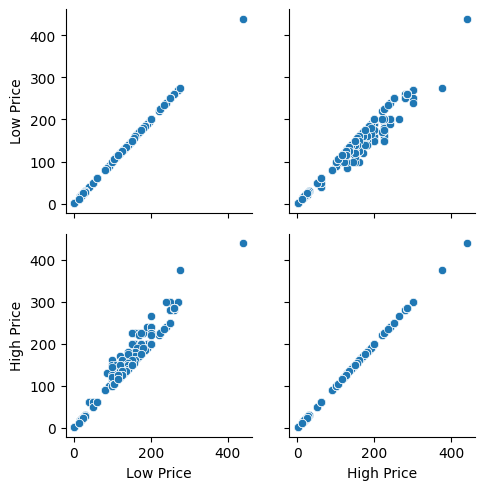

In [ ]:
import seaborn as sns
g = sns.PairGrid(all_pumpkins)
g.map(sns.scatterplot)

### Use a swarm plot

Since Color is a binary category (Orange or Not), it's called 'categorical data' and needs 'a more specialized approach to visualization'. There are other ways to visualize the relationship of this category with other variables.

You can visualize variables side-by-side with Seaborn plots.

1. Try a 'swarm' plot to show the distribution of values:

/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 63.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 21.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


<Axes: xlabel='Color', ylabel='Item Size'>

/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 79.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 35.9% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


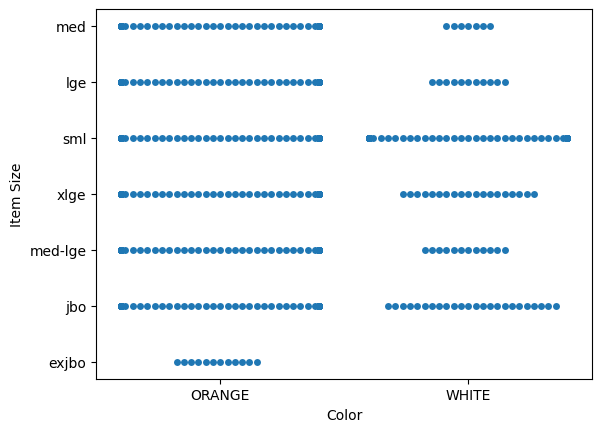

In [ ]:
sns.swarmplot(x="Color", y="Item Size", data=all_pumpkins)

### Violin plot

A 'violin' type plot is useful as you can easily visualize the way that data in the two categories is distributed. Violin plots don't work so well with smaller datasets as the distribution is displayed more 'smoothly'.

1. As parameters `x=Color`, `kind="violin"` and call `catplot()`:

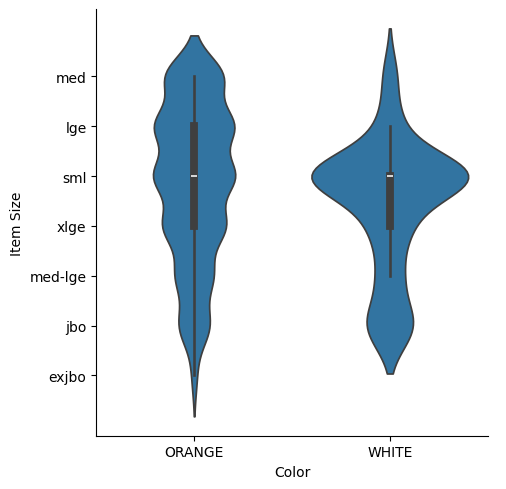

In [ ]:
sns.catplot(x="Color", y="Item Size",
                kind="violin", data=all_pumpkins)

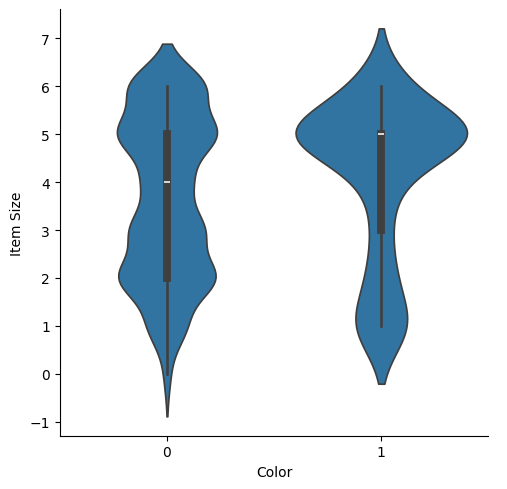

In [ ]:
sns.catplot(x="Color", y="Item Size",
            kind="violin", data=new_pumpkins)

Now that we have an idea of the relationship between the binary categories of color and the larger group of sizes, let's explore logistic regression to determine a given pumpkin's likely color.

 **🧮 Show Me The Math**

Remember how linear regression often used ordinary least squares to arrive at a value? Logistic regression relies on the concept of 'maximum likelihood'

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB

In [ ]:


Selected_features = ['Origin','Item Size','Variety','City Name','Package']
X = new_pumpkins[Selected_features]
y = new_pumpkins['Color']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

Now you can train your model, by calling `fit()` with your training data, and print out its result:

In [ ]:

log_model = LogisticRegression()
log_model.fit(X_train, y_train)
predictions =log_model.predict(X_test)

print(classification_report(y_test, predictions))
print('Predicted labels: ', predictions)
print('Accuracy: ', accuracy_score(y_test, predictions))

              precision    recall  f1-score   support

           0       0.83      0.98      0.90       166
           1       0.00      0.00      0.00        33

    accuracy                           0.81       199
   macro avg       0.42      0.49      0.45       199
weighted avg       0.69      0.81      0.75       199

Predicted labels:  [0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 1 0 0 0 0 0 0 0 0]
Accuracy:  0.8140703517587939


In [ ]:
# Predict the outcome for the test set
y_pred = log_model.predict(X_test)

# Calculate accuracy
accuracy = log_model.score(X_test, y_test)
print(accuracy)

0.8140703517587939


## Better comprehension via a confusion matrix

A '[confusion matrix](https://wikipedia.org/wiki/Confusion_matrix)' (or 'error matrix') is a table that expresses your model's true vs. false positives and negatives, thus gauging the accuracy of predictions.

In [ ]:
from sklearn.metrics import confusion_matrix
confusion_matrix(y_test, predictions)

array([[162,   4],
       [ 33,   0]])

In Scikit-learn, confusion matrices Rows (axis 0) are actual labels and columns (axis 1) are predicted labels.

hat's going on here? Let's say our model is asked to classify pumpkins between two binary categories, category 'orange' and category 'not-orange'.

- If your model predicts a pumpkin as not orange and it belongs to category 'not-orange' in reality we call it a true negative, shown by the top left number.
- If your model predicts a pumpkin as orange and it belongs to category 'not-orange' in reality we call it a false negative, shown by the bottom left number.
- If your model predicts a pumpkin as not orange and it belongs to category 'orange' in reality we call it a false positive, shown by the top right number.
- If your model predicts a pumpkin as orange and it belongs to category 'orange' in reality we call it a true positive, shown by the bottom right number


## Visualize the ROC curve of this model

This is not a bad model; its accuracy is in the 80% range so ideally you could use it to predict the color of a pumpkin given a set of variables.

Let's do one more visualization to see the so-called 'ROC' score:

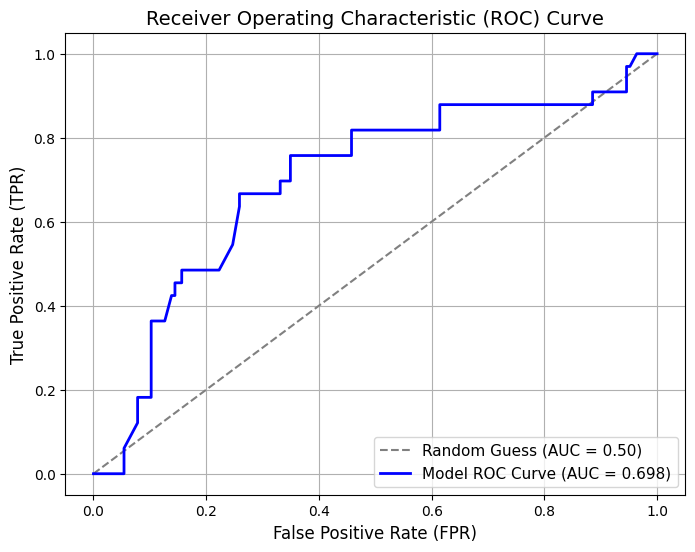

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_scores = log_model.predict_proba(X_test)
# calculate ROC curve
#fpr, tpr, thresholds = roc_curve(y_test, y_scores[:,1])
fpr, tpr, thresholds = roc_curve(y_test, y_scores[:, 1])
auc_score = roc_auc_score(y_test, y_scores[:, 1])

#sns.lineplot([0, 1], [0, 1], color='gray', linestyle='--')
#sns.lineplot(fpr, tpr)
plt.figure(figsize=(8, 6))
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label=f'Random Guess (AUC = 0.50)')

# Plot your model's ROC curve
plt.plot(fpr, tpr, color='blue', linewidth=2, label=f'Model ROC Curve (AUC = {auc_score:.3f})')

# Add labels and formatting
plt.xlabel('False Positive Rate (FPR)', fontsize=12)
plt.ylabel('True Positive Rate (TPR)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curve', fontsize=14)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True)
plt.show()

In [ ]:
auc = roc_auc_score(y_test,y_scores[:,1])
print(auc)

0.6976998904709749


In [ ]:
#

svm_model = SVC()
svm_model.fit(X_train, y_train)
predictions = svm_model.predict(X_test)

print(classification_report(y_test, predictions))
print('Accuracy: ', accuracy_score(y_test, predictions))

              precision    recall  f1-score   support

           0       0.83      1.00      0.91       166
           1       0.00      0.00      0.00        33

    accuracy                           0.83       199
   macro avg       0.42      0.50      0.45       199
weighted avg       0.70      0.83      0.76       199

Accuracy:  0.8341708542713567


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
confusion_matrix(y_test, predictions)

array([[166,   0],
       [ 33,   0]])

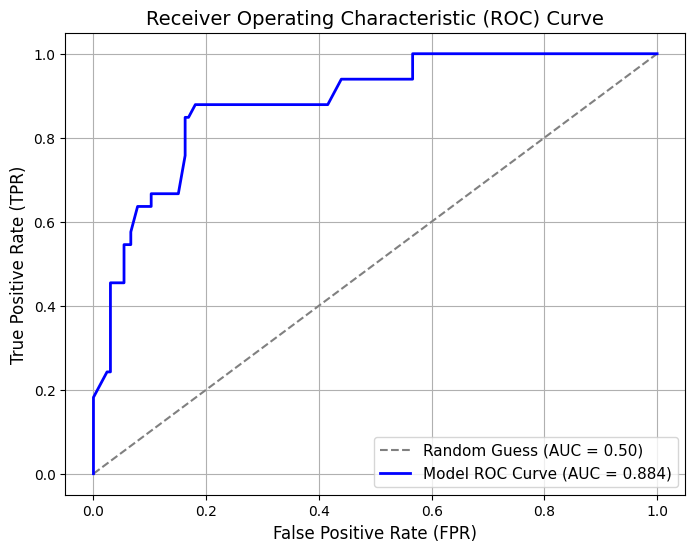

In [ ]:

y_scores = svm_model.decision_function(X_test)
# calculate ROC curve
#fpr, tpr, thresholds = roc_curve(y_test, y_scores[:,1])
#fpr, tpr, thresholds = roc_curve(y_test, y_scores[:, 1])
#auc_score = roc_auc_score(y_test, y_scores[:, 1])
fpr, tpr, thresholds = roc_curve(y_test, y_scores)
auc_score = roc_auc_score(y_test, y_scores)
#sns.lineplot([0, 1], [0, 1], color='gray', linestyle='--')
#sns.lineplot(fpr, tpr)
plt.figure(figsize=(8, 6))
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label=f'Random Guess (AUC = 0.50)')

# Plot your model's ROC curve
plt.plot(fpr, tpr, color='blue', linewidth=2, label=f'Model ROC Curve (AUC = {auc_score:.3f})')

# Add labels and formatting
plt.xlabel('False Positive Rate (FPR)', fontsize=12)
plt.ylabel('True Positive Rate (TPR)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curve', fontsize=14)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True)
plt.show()

In [ ]:


model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)
predictions = model.predict(X_test)

print(classification_report(y_test, predictions))
print('Accuracy: ', accuracy_score(y_test, predictions))

              precision    recall  f1-score   support

           0       0.96      0.92      0.94       166
           1       0.68      0.82      0.74        33

    accuracy                           0.90       199
   macro avg       0.82      0.87      0.84       199
weighted avg       0.91      0.90      0.91       199

Accuracy:  0.9045226130653267


In [ ]:


model = MultinomialNB()
model.fit(X_train, y_train)
predictions = model.predict(X_test)

print(classification_report(y_test, predictions))
print('Accuracy: ', accuracy_score(y_test, predictions))

              precision    recall  f1-score   support

           0       0.83      0.99      0.90       166
           1       0.00      0.00      0.00        33

    accuracy                           0.82       199
   macro avg       0.42      0.49      0.45       199
weighted avg       0.69      0.82      0.75       199

Accuracy:  0.8241206030150754


In [ ]:
from sklearn.neighbors import KNeighborsClassifier      # K-Nearest Neighbors
from sklearn.tree import DecisionTreeClassifier         # Decision Tree Classifier
from sklearn.ensemble import GradientBoostingClassifier # Gradient Boosting Classifier
from sklearn.neural_network import MLPClassifier        # Multi-layer Perceptron (Neural Network)

In [ ]:
Selected_features = ['Origin','Item Size','Variety','City Name','Package']
X = new_pumpkins[Selected_features]
y = new_pumpkins['Color']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

Now you can train your model, by calling fit() with your training data, and print out its result:

In [ ]:
log_model = KNeighborsClassifier()
log_model.fit(X_train, y_train)
predictions =log_model.predict(X_test)

print(classification_report(y_test, predictions))
print('Predicted labels: ', predictions)
print('Accuracy: ', accuracy_score(y_test, predictions))

              precision    recall  f1-score   support

           0       0.95      0.95      0.95       166
           1       0.75      0.73      0.74        33

    accuracy                           0.91       199
   macro avg       0.85      0.84      0.84       199
weighted avg       0.91      0.91      0.91       199

Predicted labels:  [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0
 0 0 0 0 0 0 0 1 0 0 1 0 0 0 1 0 0 0 1 0 1 1 0 0 0 0 1 0 1 0 0 0 0 0 0 0 1
 0 1 0 0 0 0 0 0 1 1 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 1 0
 0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 1 0
 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 1
 0 0 0 0 0 0 0 0 0 1 0 0 1 1]
Accuracy:  0.914572864321608


In [ ]:
# Predict the outcome for the test set
y_pred = log_model.predict(X_test)

# Calculate accuracy
accuracy = log_model.score(X_test, y_test)
print(accuracy)

0.8140703517587939


## Better comprehension via a confusion matrix

A '[confusion matrix](https://wikipedia.org/wiki/Confusion_matrix)' (or 'error matrix') is a table that expresses your model's true vs. false positives and negatives, thus gauging the accuracy of predictions.

In [ ]:
from sklearn.metrics import confusion_matrix
confusion_matrix(y_test, predictions)

array([[158,   8],
       [  9,  24]])

In Scikit-learn, confusion matrices Rows (axis 0) are actual labels and columns (axis 1) are predicted labels.

hat's going on here? Let's say our model is asked to classify pumpkins between two binary categories, category 'orange' and category 'not-orange'.

- If your model predicts a pumpkin as not orange and it belongs to category 'not-orange' in reality we call it a true negative, shown by the top left number.
- If your model predicts a pumpkin as orange and it belongs to category 'not-orange' in reality we call it a false negative, shown by the bottom left number.
- If your model predicts a pumpkin as not orange and it belongs to category 'orange' in reality we call it a false positive, shown by the top right number.
- If your model predicts a pumpkin as orange and it belongs to category 'orange' in reality we call it a true positive, shown by the bottom right number


## Visualize the ROC curve of this model

This is not a bad model; its accuracy is in the 80% range so ideally you could use it to predict the color of a pumpkin given a set of variables.

Let's do one more visualization to see the so-called 'ROC' score:

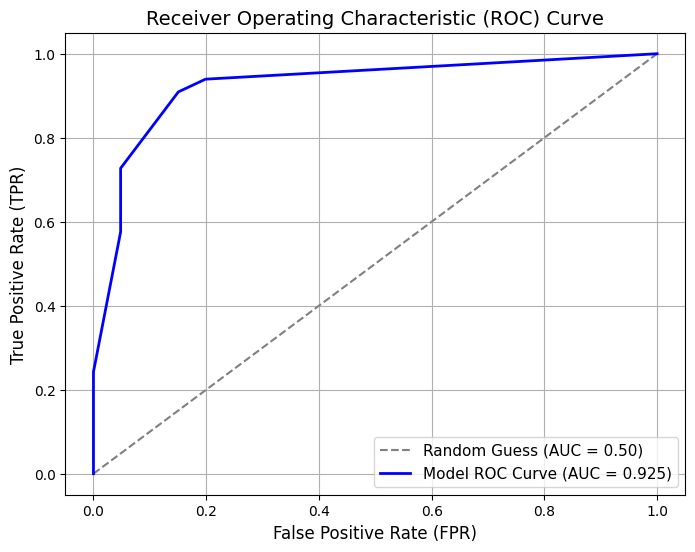

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_scores = log_model.predict_proba(X_test)
# calculate ROC curve
#fpr, tpr, thresholds = roc_curve(y_test, y_scores[:,1])
fpr, tpr, thresholds = roc_curve(y_test, y_scores[:, 1])
auc_score = roc_auc_score(y_test, y_scores[:, 1])

#sns.lineplot([0, 1], [0, 1], color='gray', linestyle='--')
#sns.lineplot(fpr, tpr)
plt.figure(figsize=(8, 6))
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label=f'Random Guess (AUC = 0.50)')

# Plot your model's ROC curve
plt.plot(fpr, tpr, color='blue', linewidth=2, label=f'Model ROC Curve (AUC = {auc_score:.3f})')

# Add labels and formatting
plt.xlabel('False Positive Rate (FPR)', fontsize=12)
plt.ylabel('True Positive Rate (TPR)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curve', fontsize=14)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True)
plt.show()

In [ ]:
auc = roc_auc_score(y_test,y_scores[:,1])
print(auc)

0.9249726177437021


In [ ]:
#

svm_model = SVC()
svm_model.fit(X_train, y_train)
predictions = svm_model.predict(X_test)

print(classification_report(y_test, predictions))
print('Accuracy: ', accuracy_score(y_test, predictions))

              precision    recall  f1-score   support

           0       0.83      1.00      0.91       166
           1       0.00      0.00      0.00        33

    accuracy                           0.83       199
   macro avg       0.42      0.50      0.45       199
weighted avg       0.70      0.83      0.76       199

Accuracy:  0.8341708542713567


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
confusion_matrix(y_test, predictions)

array([[166,   0],
       [ 33,   0]])

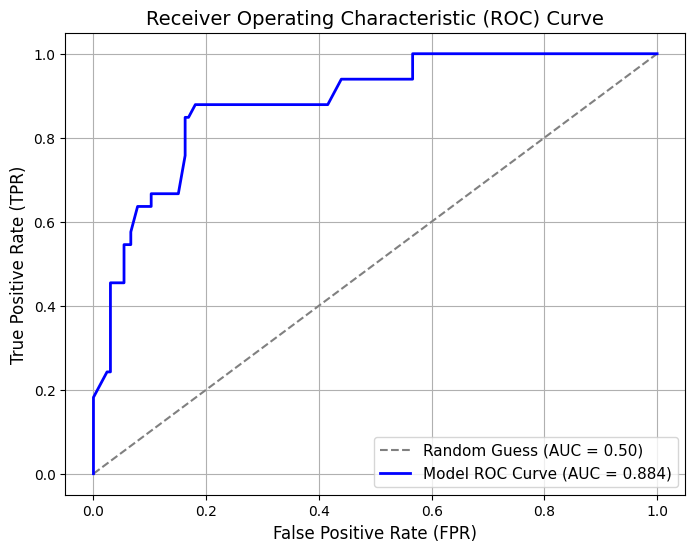

In [ ]:
y_scores = svm_model.decision_function(X_test)
# calculate ROC curve
#fpr, tpr, thresholds = roc_curve(y_test, y_scores[:,1])
#fpr, tpr, thresholds = roc_curve(y_test, y_scores[:, 1])
#auc_score = roc_auc_score(y_test, y_scores[:, 1])
fpr, tpr, thresholds = roc_curve(y_test, y_scores)
auc_score = roc_auc_score(y_test, y_scores)
#sns.lineplot([0, 1], [0, 1], color='gray', linestyle='--')
#sns.lineplot(fpr, tpr)
plt.figure(figsize=(8, 6))
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label=f'Random Guess (AUC = 0.50)')

# Plot your model's ROC curve
plt.plot(fpr, tpr, color='blue', linewidth=2, label=f'Model ROC Curve (AUC = {auc_score:.3f})')

# Add labels and formatting
plt.xlabel('False Positive Rate (FPR)', fontsize=12)
plt.ylabel('True Positive Rate (TPR)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curve', fontsize=14)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True)
plt.show()

In [ ]:
model = KNeighborsClassifier()
model.fit(X_train, y_train)
predictions = model.predict(X_test)

print(classification_report(y_test, predictions))
print('Accuracy: ', accuracy_score(y_test, predictions))

              precision    recall  f1-score   support

           0       0.95      0.95      0.95       166
           1       0.75      0.73      0.74        33

    accuracy                           0.91       199
   macro avg       0.85      0.84      0.84       199
weighted avg       0.91      0.91      0.91       199

Accuracy:  0.914572864321608


In [ ]:
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)
predictions = model.predict(X_test)

print(classification_report(y_test, predictions))
print('Accuracy: ', accuracy_score(y_test, predictions))

              precision    recall  f1-score   support

           0       0.95      0.93      0.94       166
           1       0.69      0.76      0.72        33

    accuracy                           0.90       199
   macro avg       0.82      0.85      0.83       199
weighted avg       0.91      0.90      0.91       199

Accuracy:  0.9045226130653267


In [ ]:
model = GradientBoostingClassifier()
model.fit(X_train, y_train)
predictions = model.predict(X_test)

print(classification_report(y_test, predictions))
print('Accuracy: ', accuracy_score(y_test, predictions))

              precision    recall  f1-score   support

           0       0.95      0.94      0.95       166
           1       0.71      0.76      0.74        33

    accuracy                           0.91       199
   macro avg       0.83      0.85      0.84       199
weighted avg       0.91      0.91      0.91       199

Accuracy:  0.9095477386934674


In [ ]:
model = MLPClassifier()
model.fit(X_train, y_train)
predictions = model.predict(X_test)

print(classification_report(y_test, predictions))
print('Accuracy: ', accuracy_score(y_test, predictions))

              precision    recall  f1-score   support

           0       0.86      0.98      0.91       166
           1       0.60      0.18      0.28        33

    accuracy                           0.84       199
   macro avg       0.73      0.58      0.60       199
weighted avg       0.81      0.84      0.81       199

Accuracy:  0.8442211055276382


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
